# 03 — Modelo híbrido MZA-FAO + aprendizado de máquina

Prevê o rendimento do milho 2ª safra (IBGE/PAM) a partir da simulação MZA-FAO (notebook 02) e
compara cinco formulações, todas validadas **deixando um ano inteiro de fora** (23 dobras, 2003–2025):

| | Modelo | Variáveis |
|---|---|---|
| A | Média histórica | tendência tecnológica + efeito do município |
| B | MZA calibrado | A + regressão linear: ISNA na floração e no enchimento + severidade da geada |
| C | ML puro | A + gradient boosting raso sobre o **clima bruto** por fase (chuva, Tmin, Tmax) + altitude e DTA |
| D | Híbrido | A + o mesmo gradient boosting sobre **variáveis do MZA** (eficiência hídrica PA/PPf, ISNA, déficit, geada, calor) + altitude e DTA |
| E | Híbrido MZA guiado pela física | D com **restrições monotônicas**: rendimento crescente com ISNA e PA/PPf, decrescente com déficit, geada e calor |
| F | Híbrido APSIM | o mesmo gradient boosting monotônico sobre variáveis do **APSIM NG** (rendimento simulado, nº de grãos, estresse hídrico acumulado por período, Tmin nas fases) |
| H | Híbrido AquaCrop | idem, com variáveis do **AquaCrop** (rendimento e potencial simulados, estresse de transpiração por período, Tmin) |
| I | Híbrido DSSAT | idem, com variáveis do **DSSAT CERES-Maize** (rendimento simulado, biomassa, estresse hídrico por período, dias à antese, Tmin) |
| J | Híbrido com todos | variáveis dos quatro modelos juntas |
| K | Híbrido MZA com SVR | variáveis de D sem PA/PPf e sem déficit na floração, com *support vector regression* (núcleo RBF): resposta suave, sem restrição monotônica |
| **L** | **Ensemble E + K (modelo final)** | média, em log, das previsões de E e K |

**Hipótese**: qual modelo de processos, **sem calibração**, gera as variáveis que tornam o modelo
híbrido melhor? Todos usam os mesmos insumos (clima BR-DWGD, perfil de solo da AWC + MapBiomas Solo),
a mesma janela de semeadura e o mesmo ML; só o gerador de variáveis muda (E × F × H × I).

C e D têm o mesmo algoritmo e o mesmo número de variáveis: a diferença mede o ganho de informação do
MZA. Árvores profundas com dezenas de variáveis (ExtraTrees, 70 variáveis) decoram os anos — com 22
anos de treino, o sinal climático é anual e regional, e o modelo precisa ser parcimonioso.

**Algoritmo.** Numa comparação à parte, com as mesmas variáveis de D e a mesma validação, foram testados
HGB, XGBoost, LightGBM, Random Forest, ExtraTrees, Ridge com splines, MLP e SVR, em configuração
padrão, rasa/regularizada e com ajuste aninhado de hiperparâmetros (grade avaliada por blocos de anos
dentro do treino de cada dobra). Todos ficaram entre R² 0,37 e 0,44; as configurações padrão foram as
piores (decoram os anos) e o ajuste fino quase não mudou o resultado. O SVR foi o melhor isolado
(ajuste aninhado escolheu C = 0,3 e γ = 0,05 em 22 das 23 dobras), e a média SVR + HGB monotônico
(L) foi a única melhoria com intervalo de confiança fora do zero — os dois erram de forma diferente
(resposta suave × em degraus) e metade do ensemble mantém as restrições físicas. Como o SVR não tem
restrição, PA/PPf e o déficit na floração (r = 0,97 e −0,92 com o ISNA na floração) saem dele: com as
três, o SVR repartia o efeito da água com sinais opostos e PA/PPf ficava com efeito contrário ao físico
(seção 5.1); sem elas, todas as variáveis mantêm o sentido físico, ao custo de 0,01 no R².

**Alvo.** log do rendimento. Tendência tecnológica (linear no ano) e efeito fixo de município são
estimados só com os anos de treino de cada dobra; o modelo prevê a **anomalia** em relação a eles.

**Datas de semeadura.** O IBGE não informa a data; o rendimento municipal mistura as semeaduras da
janela. No treino as variáveis de cada modelo são médias de 4 datas da janela (15/01, 05/02, 25/02, 15/03). Na predição por
data, entram as variáveis da própria data. As restrições monotônicas de E garantem que a resposta às
variáveis de cada data tenha o sentido físico esperado quando o modelo é aplicado fora da média da janela.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

from sensibilidade import PARAM, SAIDA, SENS, entrada

RAIZ = Path.cwd().parent
DADOS, RESULTADOS, FIGURAS = RAIZ / "dados", RAIZ / "resultados", RAIZ / "figuras"
if SENS:
    FIGURAS = SAIDA
SEMENTE = 42

FASES = ["estabelecimento", "vegetativo", "floracao", "enchimento", "maturacao"]
ORDEM_DATAS = [f"{d:02d}/{m:02d}" for m in (1, 2, 3) for d in (5, 15, 25)]
JANELA = ["15/01", "05/02", "25/02", "15/03"]  # mesmas 4 datas simuladas em todos os modelos
AREA_MIN_HA = 100  # descarta municípios-ano com 2ª safra residual (rendimento pouco representativo)

sim = pd.read_parquet(entrada("simulacao_mza_pr.parquet"))
# Ciclos que não fecham antes do inverno (planalto frio) deixam fases sem dados: contagens = 0,
# demais variáveis = mediana da fase (só afeta municípios sem histórico de 2ª safra).
fase_cols = [c for c in sim.columns if any(c.endswith("_" + f) for f in ["estabelecimento", "vegetativo", "floracao", "enchimento", "maturacao"])]
contagens = [c for c in fase_cols if c.startswith(("geada_", "calor_"))]
sim[contagens] = sim[contagens].fillna(0)
sim[fase_cols] = sim[fase_cols].fillna(sim[fase_cols].median())
print("Combinações com ciclo incompleto:", int(sim["ciclo_incompleto"].sum()))
sim["EC"] = sim["PA"] / sim["PPf"]  # eficiência hídrica: fração da PPf preservada pelo balanço hídrico
sim["geada_reprod"] = sim["geada_floracao"] + sim["geada_enchimento"]
sim["calor_reprod"] = sim["calor_floracao"] + sim["calor_enchimento"]
sim["frio_reprod"] = np.clip(2 - sim[["Tmin_floracao", "Tmin_enchimento"]].min(axis=1), 0, None)  # °C abaixo de 2

mun = pd.read_csv(DADOS / "municipios_pr.csv")
pam = pd.read_csv(DADOS / "ibge_pam_milho_pr.csv")
pam = pam[(pam["safra"] == 2) & (pam["rendimento_kg_ha"] > 0) & (pam["area_colhida_ha"] >= AREA_MIN_HA)]
# Valores idênticos ao do ano anterior (8,5%) indicam estimativa repetida, não levantamento: saem do treino
pam = pam.sort_values(["cod_ibge", "ano"])
pam = pam[~(pam.groupby("cod_ibge")["rendimento_kg_ha"].diff() == 0)]

apsim = pd.read_parquet(RESULTADOS / "simulacao_apsim_pr.parquet")
apsim["ap_log_rend"] = np.log(apsim["ap_rend"].clip(lower=100))
aquacrop = pd.read_parquet(RESULTADOS / "simulacao_aquacrop_pr.parquet")
aquacrop["aq_log_rend"] = np.log(aquacrop["aq_rend"].clip(lower=100))
aquacrop["aq_razao_pot"] = aquacrop["aq_razao_pot"].fillna(0)
dssat = pd.read_parquet(RESULTADOS / "simulacao_dssat_pr.parquet")
dssat["ds_log_rend"] = np.log(dssat["ds_rend"].clip(lower=100))
print(f"IBGE 2ª safra: {len(pam)} município-anos, {pam['cod_ibge'].nunique()} municípios, "
      f"{pam['ano'].min()}–{pam['ano'].max()}")

Combinações com ciclo incompleto: 0
IBGE 2ª safra: 6806 município-anos, 373 municípios, 2003–2025


## 1. Variáveis

In [2]:
VAR_ESTATICO = ["altitude_m", "dta_mm_m", "latitude", "longitude"]
VAR_FISICO = ["ISNA_floracao", "ISNA_enchimento", "frio_reprod"]                       # modelo B
VAR_CLIMA = [f"{v}_{f}" for f in ["vegetativo", "floracao", "enchimento"] for v in ["chuva", "Tmin", "Tmax"]]  # C
# D/E: variável, sentido físico (+1 crescente, −1 decrescente, 0 livre)
VAR_MZA = {"EC": 1, "ISNA_vegetativo": 1, "ISNA_floracao": 1, "ISNA_enchimento": 1, "DEF_floracao": -1,
           "frio_reprod": -1, "geada_reprod": -1, "calor_floracao": -1}
VAR_APSIM = {"ap_log_rend": 1, "ap_n_graos": 1, "ap_estresse_veg": -1, "ap_estresse_flor": -1,
             "ap_estresse_ench": -1, "ap_tmin_flor": 0, "ap_tmin_ench": 0, "ap_ciclo_dias": 0}
VAR_AQ = {"aq_log_rend": 1, "aq_razao_pot": 1, "aq_estresse_veg": -1, "aq_estresse_flor": -1,
          "aq_estresse_ench": -1, "aq_tmin_flor": 0, "aq_tmin_ench": 0, "aq_ciclo_dias": 0}
VAR_DS = {"ds_log_rend": 1, "ds_biomassa": 1, "ds_estresse_veg": -1, "ds_estresse_flor": -1,
          "ds_estresse_ench": -1, "ds_tmin_flor": 0, "ds_tmin_ench": 0, "ds_dias_antese": 0}
VARS_D = list(VAR_MZA) + VAR_ESTATICO
MONO = list(VAR_MZA.values()) + [0] * len(VAR_ESTATICO)
VARS_F = list(VAR_APSIM) + VAR_ESTATICO
MONO_F = list(VAR_APSIM.values()) + [0] * len(VAR_ESTATICO)
def conjunto(*dicts):
    nomes = [k for d in dicts for k in d] + VAR_ESTATICO
    return nomes, [v for d in dicts for v in d.values()] + [0] * len(VAR_ESTATICO)


VARS_H, MONO_H = conjunto(VAR_AQ)
VARS_I, MONO_I = conjunto(VAR_DS)
VARS_J, MONO_J = conjunto(VAR_MZA, VAR_APSIM, VAR_AQ, VAR_DS)
FASE_COLS_TODAS = [f"{v}_{f}" for f in FASES for v in ["chuva", "Tmed", "Tmax", "Tmin", "Rs", "UR", "ISNA", "DEF", "EXC", "geada", "calor"]]

# Variáveis do MZA: média ponderada das datas da janela (pesos iguais nas 4 datas, salvo na sensibilidade)
PESOS_JANELA = PARAM.get("pesos_janela", {d: 1.0 for d in JANELA})
cols_mza = sorted(set(FASE_COLS_TODAS + list(VAR_MZA) + VAR_FISICO + ["calor_reprod"]))
jm = sim[sim["semeadura"].isin(PESOS_JANELA)]
w = jm["semeadura"].map(PESOS_JANELA)
chave = [jm["cod_ibge"], jm["ano"]]
media_janela = (jm[cols_mza].mul(w, axis=0).groupby(chave).sum()
                .div(w.groupby(chave).sum(), axis=0).reset_index())
def media_da_janela(df, variaveis):
    return df[df["semeadura"].isin(JANELA)].groupby(["cod_ibge", "ano"])[list(variaveis)].mean().reset_index()


janela_apsim = media_da_janela(apsim, VAR_APSIM)
base = (pam[["cod_ibge", "ano", "rendimento_kg_ha", "area_colhida_ha"]]
        .merge(media_janela, on=["cod_ibge", "ano"])
        .merge(janela_apsim, on=["cod_ibge", "ano"])
        .merge(media_da_janela(aquacrop, VAR_AQ), on=["cod_ibge", "ano"])
        .merge(media_da_janela(dssat, VAR_DS), on=["cod_ibge", "ano"])
        .merge(mun[["cod_ibge", "municipio", "mesorregiao_oeste"] + VAR_ESTATICO], on="cod_ibge"))
base["log_y"] = np.log(base["rendimento_kg_ha"])
print(base.shape)

(6806, 94)


## 2. Validação deixando um ano de fora

In [3]:
def tendencia_e_municipio(treino):
    """log_y = a + b·ano + efeito do município, estimados só no treino."""
    reg = LinearRegression().fit(treino[["ano"]], treino["log_y"])
    resid = treino["log_y"] - reg.predict(treino[["ano"]])
    efeito = resid.groupby(treino["cod_ibge"]).mean()
    return reg, efeito


def base_prevista(df, reg, efeito):
    return reg.predict(df[["ano"]]) + df["cod_ibge"].map(efeito).fillna(0).to_numpy()


def gbm(monotonico=None):
    # Gradient boosting raso e regularizado (o sinal climático é anual: poucos graus de liberdade).
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=100,
                                         l2_regularization=1.0, monotonic_cst=monotonico, random_state=SEMENTE)


VARS_SVR = [v for v in VARS_D if v not in ("EC", "DEF_floracao")]  # sem as variáveis colineares ao ISNA


def svr():
    # Núcleo RBF; C e γ escolhidos pelo ajuste aninhado (validação por blocos de anos dentro de cada dobra)
    return make_pipeline(StandardScaler(), SVR(C=0.3, gamma=0.05, epsilon=0.05))


MODELOS = {
    "A_media_historica": None,
    "B_MZA_calibrado": "fisico",
    "C_ML_puro": (VAR_CLIMA + VAR_ESTATICO, None),
    "D_hibrido": (VARS_D, None),
    "E_hibrido_monotonico": (VARS_D, MONO),
    "F_hibrido_apsim": (VARS_F, MONO_F),
    "H_hibrido_aquacrop": (VARS_H, MONO_H),
    "I_hibrido_dssat": (VARS_I, MONO_I),
    "J_hibrido_todos": (VARS_J, MONO_J),
    "K_hibrido_svr": (VARS_SVR, "svr"),
}
FINAL = "L_ensemble_E_SVR"  # média (log) de E e K
HIBRIDOS = ["E_hibrido_monotonico", "F_hibrido_apsim", "H_hibrido_aquacrop", "I_hibrido_dssat"]

oof = base[["cod_ibge", "ano", "rendimento_kg_ha", "log_y", "mesorregiao_oeste"]].copy()
for ano in sorted(base["ano"].unique()):
    tr, te = base["ano"] != ano, base["ano"] == ano
    reg, efeito = tendencia_e_municipio(base[tr])
    b_tr, b_te = base_prevista(base[tr], reg, efeito), base_prevista(base[te], reg, efeito)
    anom_tr = base.loc[tr, "log_y"] - b_tr

    fis = LinearRegression().fit(base.loc[tr, VAR_FISICO], anom_tr)
    fis_te = fis.predict(base.loc[te, VAR_FISICO])

    for nome, spec in MODELOS.items():
        if spec is None:
            anom = 0.0
        elif spec == "fisico":
            anom = fis_te
        else:
            cols, mono = spec
            modelo = svr() if mono == "svr" else gbm(mono)
            anom = modelo.fit(base.loc[tr, cols], anom_tr).predict(base.loc[te, cols])
        oof.loc[te, nome] = b_te + anom

oof[FINAL] = oof[["E_hibrido_monotonico", "K_hibrido_svr"]].mean(axis=1)
nomes = list(MODELOS) + [FINAL]
print("ok")

ok


In [4]:
def metricas(df, col):
    y, p = df["rendimento_kg_ha"], np.exp(df[col])
    anual = df.assign(p=p).groupby("ano")[["rendimento_kg_ha", "p"]].mean()
    return {
        "R2": r2_score(y, p),
        "RMSE_kg_ha": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE_kg_ha": mean_absolute_error(y, p),
        "r_anual_estadual": anual.corr().iloc[0, 1],
        "R2_anual_estadual": r2_score(anual["rendimento_kg_ha"], anual["p"]),
    }


tab = pd.DataFrame({n: metricas(oof, n) for n in nomes}).T
ref = tab.loc["A_media_historica", "RMSE_kg_ha"]
tab["ganho_sobre_A_%"] = 100 * (1 - tab["RMSE_kg_ha"] / ref)
tab.to_csv(SAIDA / "validacao_loyo_modelos.csv")
tab.round(3)

,R2,RMSE_kg_ha,MAE_kg_ha,r_anual_estadual,R2_anual_estadual,ganho_sobre_A_%
A_media_historica,0.259,1207.017,955.907,0.595,0.313,0.000
B_MZA_calibrado,0.346,1134.167,889.450,0.755,0.556,6.036
C_ML_puro,0.361,1120.606,880.166,0.770,0.580,7.159
D_hibrido,0.410,1077.222,838.960,0.826,0.664,10.753
E_hibrido_monotonico,0.403,1083.588,841.967,0.801,0.635,10.226
F_hibrido_apsim,0.334,1144.514,904.799,0.728,0.513,5.178
H_hibrido_aquacrop,0.245,1218.148,958.477,0.665,0.422,-0.922
I_hibrido_dssat,0.334,1144.196,895.043,0.735,0.523,5.205
J_hibrido_todos,0.364,1118.782,876.334,0.760,0.571,7.310
K_hibrido_svr,0.427,1061.480,826.324,0.831,0.682,12.058


### As diferenças entre os geradores de variáveis são reais?

Bootstrap por **anos** (os anos são a unidade independente da validação; 2.000 reamostragens): para
cada híbrido, a diferença de RMSE em relação ao híbrido MZA (E). Intervalo de 95% que não cruza zero
indica diferença robusta à escolha dos anos.

In [5]:
rng_b = np.random.default_rng(SEMENTE)
anos_u = np.sort(oof["ano"].unique())
erro2 = {n: (oof["rendimento_kg_ha"] - np.exp(oof[n])) ** 2 for n in nomes}
por_ano = pd.DataFrame({n: e.groupby(oof["ano"]).sum() for n, e in erro2.items()})
cont = oof.groupby("ano").size()
amostras = rng_b.choice(anos_u, size=(2000, len(anos_u)))
rmse_boot = {n: np.sqrt(por_ano[n].to_numpy()[np.searchsorted(anos_u, amostras)].sum(1)
                        / cont.to_numpy()[np.searchsorted(anos_u, amostras)].sum(1)) for n in nomes}
ref_b = rmse_boot["E_hibrido_monotonico"]
boot = pd.DataFrame({n: {"dif_RMSE_vs_E": np.median(rmse_boot[n] - ref_b),
                         "IC95_inf": np.percentile(rmse_boot[n] - ref_b, 2.5),
                         "IC95_sup": np.percentile(rmse_boot[n] - ref_b, 97.5),
                         "P(melhor que E)": np.mean(rmse_boot[n] < ref_b)} for n in nomes if n != "E_hibrido_monotonico"}).T
boot.to_csv(SAIDA / "comparacao_geradores_bootstrap.csv")
boot.round(2)

,dif_RMSE_vs_E,IC95_inf,IC95_sup,P(melhor que E)
A_media_historica,118.43,-48.60,295.63,0.09
B_MZA_calibrado,51.18,-20.84,114.52,0.08
C_ML_puro,38.98,-36.17,97.63,0.13
D_hibrido,-5.51,-47.52,29.32,0.61
F_hibrido_apsim,59.92,12.19,115.29,0.01
H_hibrido_aquacrop,132.30,9.90,262.58,0.02
I_hibrido_dssat,59.72,26.99,96.58,0.00
J_hibrido_todos,35.35,11.91,56.87,0.00
K_hibrido_svr,-22.10,-61.90,17.98,0.86
L_ensemble_E_SVR,-25.05,-43.46,-6.20,1.00


### Desempenho por ano (o que importa para o risco: acertar os anos de quebra)

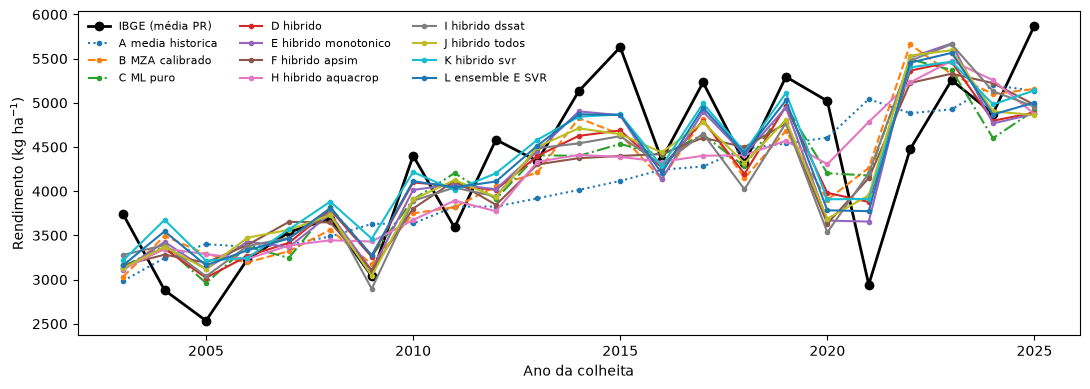

In [6]:
anual = oof.assign(**{n: np.exp(oof[n]) for n in nomes}).groupby("ano")[["rendimento_kg_ha"] + nomes].mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(anual.index, anual["rendimento_kg_ha"], "ko-", lw=2, label="IBGE (média PR)")
estilos = {"A_media_historica": ":", "B_MZA_calibrado": "--", "C_ML_puro": "-."}
for n in nomes:
    ax.plot(anual.index, anual[n], estilos.get(n, "-"), marker=".", label=n.replace("_", " "))
ax.set(xlabel="Ano da colheita", ylabel="Rendimento (kg ha$^{-1}$)")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_validacao_anual.png", dpi=300)

## 3. Intervalos de predição (conformal)

Para cada ano de teste, os quantis vêm dos resíduos (em log) dos **outros** anos — conformal
"deixando um ano de fora". A cobertura nominal de 80% (P10–P90) é verificada ano a ano.

In [7]:
# Gerador de variáveis vencedor entre os híbridos monotônicos (E, F, H, I) → combinado com o SVR (L)
GERADOR = tab.loc[HIBRIDOS, "RMSE_kg_ha"].idxmin()
MELHOR = FINAL
VARS_FINAL, MONO_FINAL = MODELOS[GERADOR]
print("Menor RMSE:", tab["RMSE_kg_ha"].idxmin(), "| gerador:", GERADOR, "| modelo final:", MELHOR)
res = oof["log_y"] - oof[MELHOR]
q = {}
for ano in sorted(oof["ano"].unique()):
    r = res[oof["ano"] != ano]
    q[ano] = r.quantile([0.10, 0.50, 0.90]).to_numpy()
qa = oof["ano"].map(q)
oof["P10"] = np.exp(oof[MELHOR] + qa.str[0])
oof["P50"] = np.exp(oof[MELHOR] + qa.str[1])
oof["P90"] = np.exp(oof[MELHOR] + qa.str[2])
dentro = oof["rendimento_kg_ha"].between(oof["P10"], oof["P90"])
print(f"Melhor modelo: {MELHOR}; cobertura P10–P90 = {dentro.mean():.1%} (nominal 80%)")
oof.to_parquet(SAIDA / "previsoes_fora_amostra.parquet", index=False)
dentro.groupby(oof["ano"]).mean().round(2).to_frame("cobertura").T

Menor RMSE: L_ensemble_E_SVR | gerador: E_hibrido_monotonico | modelo final: L_ensemble_E_SVR
Melhor modelo: L_ensemble_E_SVR; cobertura P10–P90 = 79.4% (nominal 80%)


ano,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
cobertura,0.72,0.72,0.65,0.76,0.8,0.89,0.77,0.92,0.87,0.85,...,0.76,0.91,0.84,0.89,0.44,0.54,0.68,0.89,0.87,0.72


## 4. Análises por fase fenológica

### 4.1 Variáveis por fase × data de semeadura

semeadura,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
ciclo_dias,105.20,109.69,115.79,124.13,132.58,140.59,146.81,153.46,158.49
EC,0.43,0.37,0.33,0.30,0.28,0.28,0.29,0.30,0.31
geada_reprod,0.04,0.12,0.29,0.57,0.89,1.21,1.42,1.55,1.52


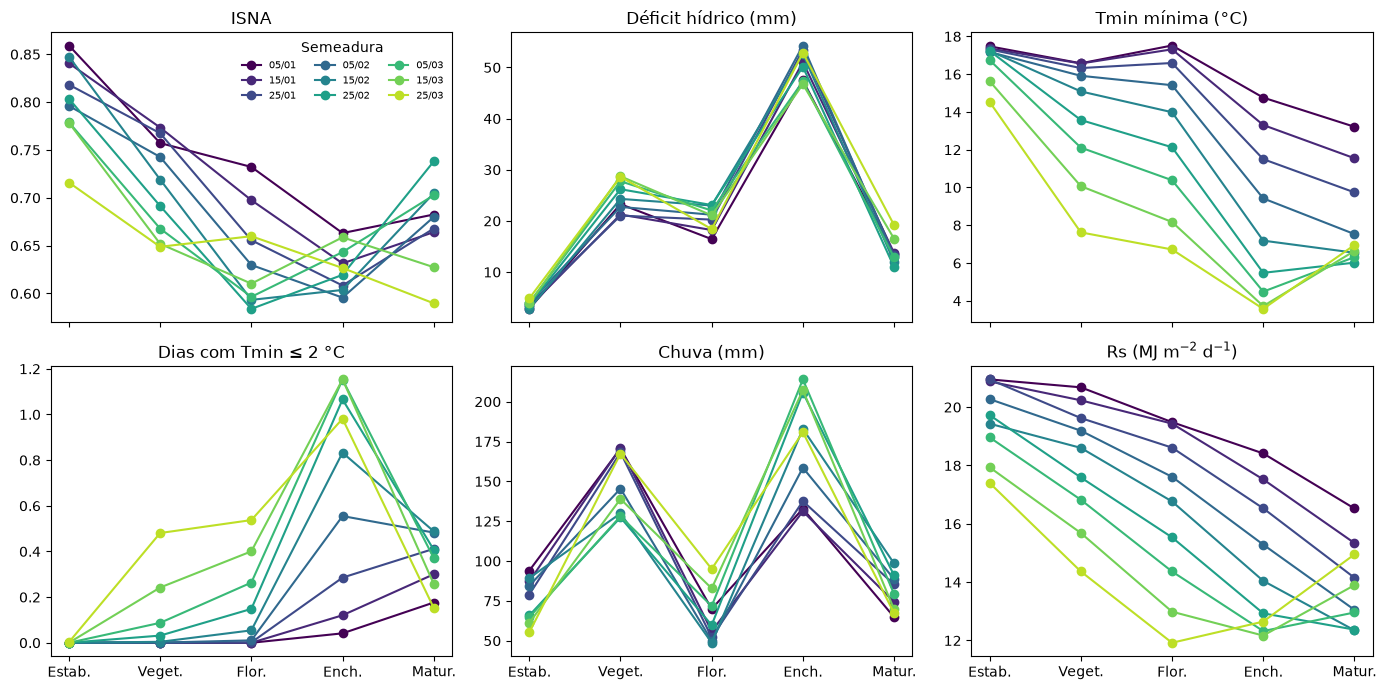

In [8]:
VARS_FIG = [("ISNA", "ISNA"), ("DEF", "Déficit hídrico (mm)"), ("Tmin", "Tmin mínima (°C)"),
            ("geada", "Dias com Tmin ≤ 2 °C"), ("chuva", "Chuva (mm)"), ("Rs", "Rs (MJ m$^{-2}$ d$^{-1}$)")]
fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
cores = plt.cm.viridis(np.linspace(0, 0.9, len(ORDEM_DATAS)))
for ax, (v, rot) in zip(axs.flat, VARS_FIG):
    med = sim.groupby("semeadura")[[f"{v}_{f}" for f in FASES]].mean().loc[ORDEM_DATAS]
    for (data, linha), c in zip(med.iterrows(), cores):
        ax.plot(range(len(FASES)), linha.values, marker="o", color=c, label=data)
    ax.set_title(rot)
    ax.set_xticks(range(len(FASES)), ["Estab.", "Veget.", "Flor.", "Ench.", "Matur."])
axs[0, 0].legend(fontsize=7, ncol=3, frameon=False, title="Semeadura")
plt.tight_layout()
fig.savefig(FIGURAS / "fig_variaveis_fase_data.png", dpi=300)
sim.groupby("semeadura")[["ciclo_dias", "EC", "geada_reprod"]].mean().loc[ORDEM_DATAS].round(2).T

### 4.2 Correlação por fase com a anomalia de produtividade

Separada em duas escalas: **entre anos** (médias estaduais por ano) e **entre municípios** (dentro
de cada ano, média das correlações). A anomalia é o resíduo do modelo A ajustado com todos os anos.

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-p

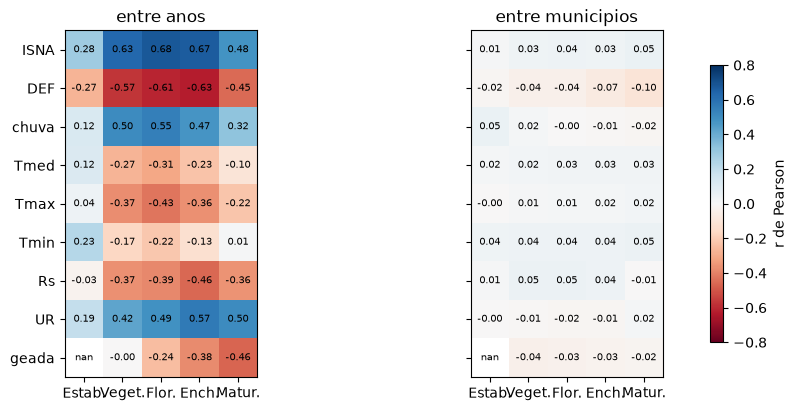

In [9]:
reg_all, efeito_all = tendencia_e_municipio(base)
base["anomalia"] = base["log_y"] - base_prevista(base, reg_all, efeito_all)
VARS_COR = ["ISNA", "DEF", "chuva", "Tmed", "Tmax", "Tmin", "Rs", "UR", "geada"]
linhas = []
for v in VARS_COR:
    for f in FASES:
        col = f"{v}_{f}"
        anual_m = base.groupby("ano")[["anomalia", col]].mean()
        espacial = base.groupby("ano").apply(lambda g: g["anomalia"].corr(g[col]), include_groups=False).mean()
        linhas.append({"variavel": v, "fase": f, "entre_anos": anual_m.corr().iloc[0, 1], "entre_municipios": espacial})
cor = pd.DataFrame(linhas)
cor.to_csv(SAIDA / "correlacao_fase.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, escala in zip(axs, ["entre_anos", "entre_municipios"]):
    m = cor.pivot(index="variavel", columns="fase", values=escala).loc[VARS_COR, FASES]
    im = ax.imshow(m, cmap="RdBu", vmin=-0.8, vmax=0.8)
    ax.set_xticks(range(len(FASES)), ["Estab.", "Veget.", "Flor.", "Ench.", "Matur."])
    ax.set_yticks(range(len(VARS_COR)), VARS_COR)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(escala.replace("_", " "))
fig.colorbar(im, ax=axs, shrink=0.8, label="r de Pearson")
fig.savefig(FIGURAS / "fig_correlacao_fase.png", dpi=300, bbox_inches="tight")

### 4.3 Importância por fase (SHAP do modelo final, ensemble E + SVR)

O SHAP é linear no modelo: o do ensemble é a média do SHAP de cada componente — exato (TreeSHAP)
para o HGB e por permutação para o SVR (2 permutações antitéticas por linha, fundo de 40
município-anos; o SVR prevê ~1.400 linhas/s, o que limita a amostra a 200 município-anos).

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo B (todos os anos): {'ISNA_floracao': np.float64(0.4988), 'ISNA_enchimento': np.float64(0.4722), 'frio_reprod': np.float64(-0.0678)}


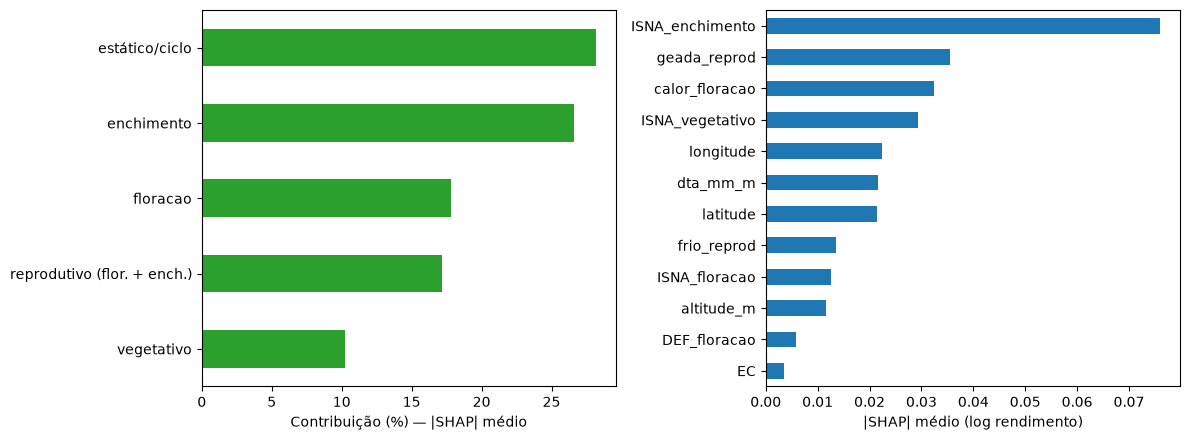

In [10]:
import shap

anom_all = base["anomalia"]
X = base[VARS_FINAL]
ml_final = gbm(MONO_FINAL).fit(X, anom_all)
svr_final = svr().fit(X[VARS_SVR], anom_all)


def prever_svr(x):
    return svr_final.predict(pd.DataFrame(x, columns=VARS_FINAL)[VARS_SVR])


def prever_final(x):
    x = pd.DataFrame(x, columns=VARS_FINAL)
    return (ml_final.predict(x) + prever_svr(x)) / 2


amostra = X.sample(200, random_state=SEMENTE)
shap_hgb = shap.TreeExplainer(ml_final).shap_values(amostra)
expl_svr = shap.PermutationExplainer(svr_final.predict, X[VARS_SVR].sample(40, random_state=SEMENTE + 1))
shap_svr = pd.DataFrame(0.0, index=amostra.index, columns=VARS_FINAL)  # EC e DEF não entram no SVR
shap_svr[VARS_SVR] = expl_svr(amostra[VARS_SVR], max_evals=2 * (2 * len(VARS_SVR) + 1), silent=True).values
shap_svr = shap_svr.to_numpy()
valores = (shap_hgb + shap_svr) / 2
imp = pd.Series(np.abs(valores).mean(axis=0), index=X.columns)


def grupo(col):
    if col.endswith("_reprod"):
        return "reprodutivo (flor. + ench.)"  # geada/frio somados na floração e no enchimento
    for f in FASES:
        if col.endswith("_" + f):
            return f
    for p, f in {"_veg": "vegetativo", "_flor": "floracao", "_ench": "enchimento"}.items():
        if col.endswith(p):
            return f
    return "estático/ciclo"


por_fase = imp.groupby(imp.index.map(grupo)).sum().sort_values(ascending=False)
por_var = imp.sort_values(ascending=False).head(15)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
(por_fase / por_fase.sum() * 100).plot.barh(ax=a1, color="tab:green")
a1.invert_yaxis()
a1.set_xlabel("Contribuição (%) — |SHAP| médio")
por_var.plot.barh(ax=a2, color="tab:blue")
a2.invert_yaxis()
a2.set_xlabel("|SHAP| médio (log rendimento)")
plt.tight_layout()
fig.savefig(FIGURAS / "fig_shap_fase.png", dpi=300)
fis_all = LinearRegression().fit(base[VAR_FISICO], anom_all)
print("Modelo B (todos os anos):", dict(zip(VAR_FISICO, fis_all.coef_.round(4))))

## 5. Predição por município × ano × data de semeadura

Modelo final treinado com todos os anos. O rendimento é expresso no **nível tecnológico de 2025**
(tendência avaliada em 2025), para que os 27 anos de clima (1999–2025) sejam cenários comparáveis
para a análise de risco. Quantis pelos resíduos fora da amostra (seção 3).

In [11]:
pred = (sim.merge(apsim[["cod_ibge", "ano", "semeadura"] + list(VAR_APSIM)], on=["cod_ibge", "ano", "semeadura"], how="left")
        .merge(aquacrop[["cod_ibge", "ano", "semeadura"] + list(VAR_AQ)], on=["cod_ibge", "ano", "semeadura"], how="left")
        .merge(dssat[["cod_ibge", "ano", "semeadura"] + list(VAR_DS)], on=["cod_ibge", "ano", "semeadura"], how="left")
        .merge(mun[["cod_ibge"] + VAR_ESTATICO], on="cod_ibge"))
completo = pred[VARS_FINAL].notna().all(axis=1)
print(f"Combinações com todas as variáveis de {MELHOR}: {completo.mean():.1%}"
      " (o vencedor precisa ser simulado nas 9 datas × 399 municípios para a etapa de decisão)")
pred = pred[completo]
nivel = reg_all.predict(pd.DataFrame({"ano": [2025]}))[0] + pred["cod_ibge"].map(efeito_all)
sem_hist = nivel.isna()
print(f"Municípios sem histórico de 2ª safra no IBGE (efeito = média): {pred.loc[sem_hist, 'cod_ibge'].nunique()}")
nivel = nivel.fillna(reg_all.predict(pd.DataFrame({"ano": [2025]}))[0])

centro = nivel + prever_final(pred[VARS_FINAL])
qs = res.quantile([0.10, 0.50, 0.90]).to_numpy()
saida = pred[["cod_ibge", "ano", "semeadura", "data_maturacao", "ciclo_dias", "EC", "geada_reprod"]].copy()
saida["sem_historico_ibge"] = sem_hist.to_numpy()
for nome, qv in zip(["P10", "P50", "P90"], qs):
    saida[f"rend_{nome}_kg_ha"] = np.exp(centro + qv)
saida.to_parquet(SAIDA / "produtividade_prevista_pr.parquet", index=False)
saida.groupby("semeadura")[["rend_P10_kg_ha", "rend_P50_kg_ha", "rend_P90_kg_ha"]].mean().loc[ORDEM_DATAS].round(0)

Combinações com todas as variáveis de L_ensemble_E_SVR: 100.0% (o vencedor precisa ser simulado nas 9 datas × 399 municípios para a etapa de decisão)
Municípios sem histórico de 2ª safra no IBGE (efeito = média): 26


,rend_P10_kg_ha,rend_P50_kg_ha,rend_P90_kg_ha
semeadura,,,
05/01,3761.0,5617.0,7347.0
15/01,3632.0,5424.0,7095.0
25/01,3569.0,5330.0,6971.0
05/02,3472.0,5184.0,6781.0
15/02,3421.0,5108.0,6681.0
25/02,3399.0,5076.0,6640.0
05/03,3465.0,5175.0,6769.0
15/03,3501.0,5228.0,6838.0
25/03,3489.0,5209.0,6814.0


### 5.1 O ensemble mantém o sentido físico?

O SVR não tem restrição monotônica. Para cada variável com sentido físico definido, a resposta
média (dependência parcial sobre 1.000 município-anos) é avaliada do percentil 5 ao 95; conta-se a
fração de passos contra o sentido esperado. Em seguida, a curva média de rendimento por data de
semeadura do ensemble é comparada com a de E.

In [12]:
amostra_pd = X.sample(1000, random_state=SEMENTE)
linhas = []
for v, sentido in VAR_MZA.items():
    grade = np.quantile(X[v], np.linspace(0.05, 0.95, 15))
    for nome, f in [("E", ml_final.predict), ("SVR", prever_svr), ("ensemble", prever_final)]:
        cv = np.array([f(amostra_pd.assign(**{v: g})).mean() for g in grade])  # SVR: constante em EC e DEF
        passos = np.diff(cv) * sentido
        linhas.append({"variavel": v, "modelo": nome, "frac_contra": float(np.mean(passos < -1e-4)),
                       "efeito_total": float((cv[-1] - cv[0]) * sentido)})
fisica = pd.DataFrame(linhas).pivot(index="variavel", columns="modelo", values=["frac_contra", "efeito_total"])
print("frac_contra = fração dos passos contra o sentido físico; efeito_total > 0 = sentido correto (log)")
display(fisica.round(3))

so_e = np.exp(nivel + ml_final.predict(pred[VARS_FINAL]) + qs[1])
comp = pd.DataFrame({"cod_ibge": pred["cod_ibge"].to_numpy(), "semeadura": pred["semeadura"].to_numpy(),
                     "E": np.asarray(so_e), "ensemble": saida["rend_P50_kg_ha"].to_numpy()})
media_mun = comp.groupby(["cod_ibge", "semeadura"])[["E", "ensemble"]].mean()
mesma = (media_mun["E"].groupby(level=0).idxmax().str[1] == media_mun["ensemble"].groupby(level=0).idxmax().str[1]).mean()
print(f"Data de maior P50 médio igual entre E e ensemble em {mesma:.0%} dos municípios")
comp.groupby("semeadura")[["E", "ensemble"]].mean().loc[ORDEM_DATAS].round(0).T

frac_contra = fração dos passos contra o sentido físico; efeito_total > 0 = sentido correto (log)


frac_contra                 efeito_total                
modelo                    E    SVR ensemble            E    SVR ensemble
variavel                                                                
DEF_floracao            0.0  0.000    0.000        0.060 -0.000    0.030
EC                      0.0  0.000    0.000        0.021  0.000    0.011
ISNA_enchimento         0.0  0.429    0.357        0.354  0.248    0.301
ISNA_floracao           0.0  0.071    0.071        0.035  0.064    0.049
ISNA_vegetativo         0.0  0.429    0.429        0.146  0.147    0.146
calor_floracao          0.0  0.000    0.000        0.161  0.143    0.152
frio_reprod             0.0  0.000    0.000        0.046  0.142    0.094
geada_reprod            0.0  0.000    0.000        0.140  0.188    0.164

Data de maior P50 médio igual entre E e ensemble em 88% dos municípios


semeadura,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
E,5814.0,5633.0,5491.0,5300.0,5215.0,5151.0,5216.0,5291.0,5273.0
ensemble,5617.0,5424.0,5330.0,5184.0,5108.0,5076.0,5175.0,5228.0,5209.0
